# Zomato EDA - Part 2 : Univariate (cont.), Bivariate & Multivariate Analysis

In `Zomato_EDA.ipynb` (Part 1) we did :
- Data cleaning & preprocessing
- Some feature engineering (`price_category`, `ratings_category`)
- Univariate analysis on `rate` and `cost_for_two`

-----------------------------------------------

### In this notebook we will :
1. Finish the **univariate analysis** (votes + all categorical columns)
2. Do **bivariate analysis** : how 2 variables behave together (eg : does online ordering affect rating ?)
3. Do **multivariate analysis** : correlation heatmap, pivot tables etc.
4. Write down the **insights** that will help us later while building the recommendation system

> We will load the `zomato_cleaned.csv` which we saved at the end of Part 1, so no need to clean everything again ;)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
sns.set_style('whitegrid')
sns.set_palette("husl")

plt.rcParams['figure.figsize'] = (12,6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
%matplotlib inline

In [4]:
import os

# folder to save the plots (same folder used in Part 1)
os.makedirs("plots", exist_ok=True)

## Loading the cleaned dataset

In [5]:
df = pd.read_csv("zomato_cleaned.csv")

print("Shape: ", df.shape)
df.head()

Shape:  (51632, 12)


,address,name,online_order,book_table,rate,votes,location,rest_type,cuisines,cost_for_two,meal_type,city
0,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1,775,Banashankari,Casual Dining,"North Indian, Mughlai, Chinese",800.0,Buffet,Banashankari
1,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1,787,Banashankari,Casual Dining,"Chinese, North Indian, Thai",800.0,Buffet,Banashankari
2,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8,918,Banashankari,"Cafe, Casual Dining","Cafe, Mexican, Italian",800.0,Buffet,Banashankari
3,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7,88,Banashankari,Quick Bites,"South Indian, North Indian",300.0,Buffet,Banashankari
4,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8,166,Basavanagudi,Casual Dining,"North Indian, Rajasthani",600.0,Buffet,Banashankari


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51632 entries, 0 to 51631
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   address       51632 non-null  str    
 1   name          51632 non-null  str    
 2   online_order  51632 non-null  str    
 3   book_table    51632 non-null  str    
 4   rate          51632 non-null  float64
 5   votes         51632 non-null  int64  
 6   location      51632 non-null  str    
 7   rest_type     51632 non-null  str    
 8   cuisines      51632 non-null  str    
 9   cost_for_two  51632 non-null  float64
 10  meal_type     51632 non-null  str    
 11  city          51632 non-null  str    
dtypes: float64(2), int64(1), str(9)
memory usage: 4.7 MB


### Re-creating the engineered features

The cleaned csv was saved **before** the feature engineering step in Part 1, so the encoded / binned columns are not inside the file.

Will quickly re-create them here (same logic as Part 1) :
- `online_order_enc`, `book_table_enc` : Yes/No -> 1/0
- `price_category` : binning on `cost_for_two`
- `ratings_category` : binning on `rate`

In [7]:
df["online_order_enc"] = df["online_order"].map({"Yes" : 1, "No" : 0})
df["book_table_enc"] = df["book_table"].map({"Yes" : 1, "No" : 0})

In [8]:
def price_bucket(cost):
    if cost <= 200:
        return "Budget"
    elif cost <= 500:
        return "Affordable"
    elif cost <= 1000:
        return "Mid-Range"
    elif cost <= 1500:
        return "Premium"
    else:
        return "Luxury"

df["price_category"] = df["cost_for_two"].apply(price_bucket)

# keeping the order fixed so that plots come in Budget -> Luxury order (not alphabetical)
price_order = ["Budget", "Affordable", "Mid-Range", "Premium", "Luxury"]
df["price_category"] = pd.Categorical(df["price_category"], categories=price_order, ordered=True)

In [9]:
bin_rates = [0, 2.5, 3.5, 4.0, 4.5, 5.0]
bin_labels = ["Poor", "Average", "Good", "Very Good", "Excellent"]

df["ratings_category"] = pd.cut(df["rate"], bins = bin_rates, labels = bin_labels)

### A small but IMPORTANT note about the `rate` column

In Part 1 we filled ~20% missing ratings (`NEW` / `-` / `NaN`) with the **median = 3.7**.

That was fine for cleaning, but while analysing ratings these filled values can fool us,
because thousands of restaurants are now sitting exactly at `3.7` artificially.

Lets check : restaurants which have `votes == 0` are basically the ones which were never rated.

In [10]:
print("Rows with votes == 0          : ", (df["votes"] == 0).sum())
print("Rows with votes == 0 & rate 3.7: ", ((df["votes"] == 0) & (df["rate"] == 3.7)).sum())

Rows with votes == 0          :  10005
Rows with votes == 0 & rate 3.7:  9991


Almost all `votes == 0` rows have rating exactly `3.7` => these are the median filled ones.

So, for any **rating related analysis**, we will use a separate dataframe `df_rated` which only keeps restaurants having at least 1 vote.
For other things (cost, location, cuisines etc.) we will use full `df`.

In [11]:
# creating a flag column, will be useful later also
df["is_rated"] = (df["votes"] > 0).astype(int)

df_rated = df[df["is_rated"] == 1].copy()

print("Full df   : ", df.shape)
print("Rated df  : ", df_rated.shape)

Full df   :  (51632, 17)
Rated df  :  (41627, 17)


### One more thing : the same restaurant appears multiple times !

In this dataset the same restaurant (same `name` + `address`) is listed again and again under different
`meal_type` (Delivery, Dine-Out, Desserts ...) and different `city` (listing area).

Lets see how many **actual unique** restaurants we have.

In [12]:
n_unique = df[["name", "address"]].drop_duplicates().shape[0]

print("Total rows                       : ", len(df))
print("Unique restaurants (name+address): ", n_unique)
print(f"Avg times a restaurant repeats    :  {len(df)/n_unique:.2f}")

Total rows                       :  51632
Unique restaurants (name+address):  12498
Avg times a restaurant repeats    :  4.13


So on average each restaurant appears ~4 times.

For counting things like **"how many restaurants in a location"** or **"most popular chains"** we will use a
de-duplicated version `df_unique` (one row per restaurant), otherwise the counts would be inflated.

In [13]:
df_unique = df.drop_duplicates(subset=["name", "address"]).copy()
print("df_unique shape: ", df_unique.shape)

df_unique shape:  (12498, 17)


------------------------------------------------------------------------------

# Univariate Analysis (continued)

Already done in Part 1 : `rate` & `cost_for_two`

Remaining :
- Votes
- Online order availability
- Table Booking availability
- Meal Type
- Restaurant Type
- Cuisines
- Price Category
- Top Locations by Restaurant count
- Top Restaurant chains

### Votes Distrb.

In [14]:
print(df["votes"].describe())
print(f"Skewness: {df['votes'].skew():.3f}")
print(f"Kurtosis: {df['votes'].kurtosis():.3f}")

count    51632.000000
mean       283.159901
std        803.125144
min          0.000000
25%          7.000000
50%         41.000000
75%        198.000000
max      16832.000000
Name: votes, dtype: float64
Skewness: 7.567
Kurtosis: 89.275


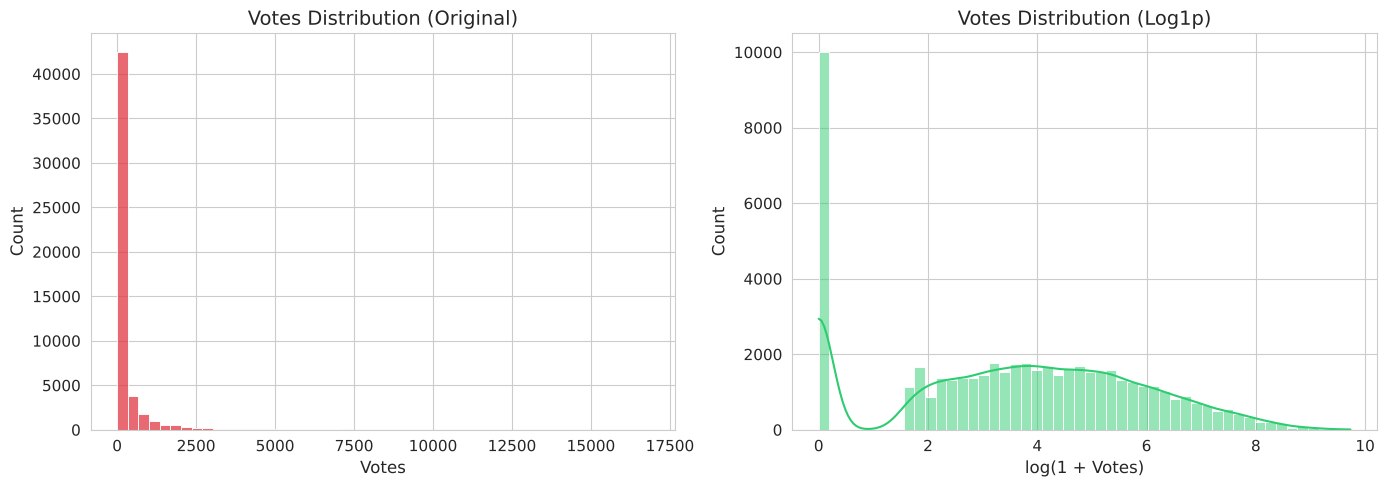

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["votes"], bins=50, color="#E23744", ax=axes[0])
axes[0].set_title("Votes Distribution (Original)")
axes[0].set_xlabel("Votes")

# votes are hugely skewed, so lets see on log scale also
sns.histplot(np.log1p(df["votes"]), bins=50, kde=True, color="#2ECC71", ax=axes[1])
axes[1].set_title("Votes Distribution (Log1p)")
axes[1].set_xlabel("log(1 + Votes)")

plt.tight_layout()
plt.savefig("plots/votes_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
print(f"Skewness after log1p : {np.log1p(df['votes']).skew():.3f}")

Skewness after log1p : -0.095


-------------------------------------------------------
### Insights :

- `votes` is **extremely right skewed** (skewness ~7.5 , even more than `cost_for_two`).
- 50% of restaurants have **41 or less votes**, but a few restaurants have more than **16k votes** !
- ~10k rows have **0 votes** (the NEW / unrated ones).
- After `log1p` the skewness drops a lot, so if we use votes as a feature in a model, we will use `log1p(votes)`.

Votes is basically a proxy for **popularity** of a restaurant -> very useful for the recommendation part (popular + good rating = safe recommendation).

### Online Order & Table Booking

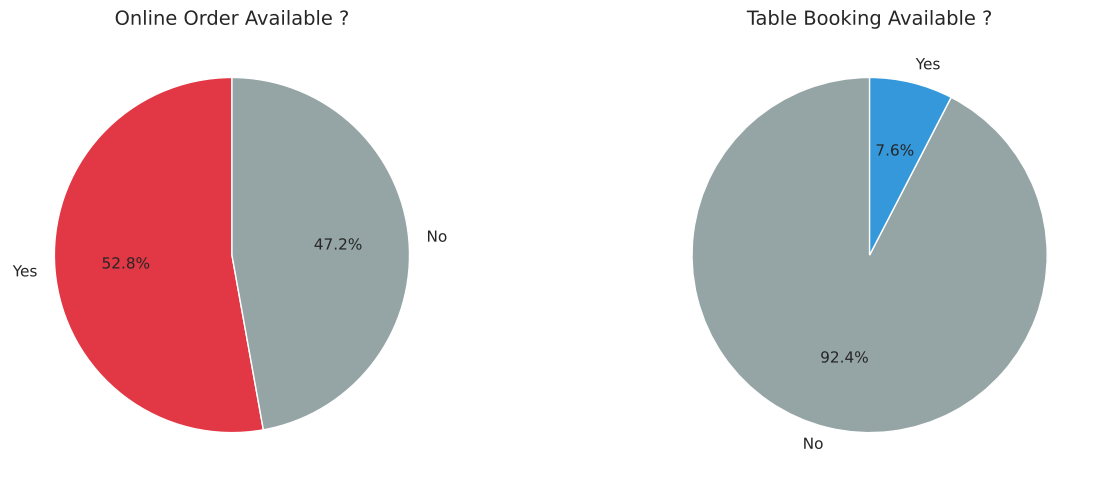

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_unique["online_order"].value_counts().plot.pie(
    autopct="%1.1f%%", colors=["#E23744", "#95A5A6"], startangle=90, ax=axes[0]
)
axes[0].set_title("Online Order Available ?")
axes[0].set_ylabel("")

df_unique["book_table"].value_counts().plot.pie(
    autopct="%1.1f%%", colors=["#95A5A6", "#3498DB"], startangle=90, ax=axes[1]
)
axes[1].set_title("Table Booking Available ?")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("plots/online_order_book_table_pie.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
print(df_unique["online_order"].value_counts(normalize=True).round(3))
print()
print(df_unique["book_table"].value_counts(normalize=True).round(3))

online_order
Yes    0.528
No     0.472
Name: proportion, dtype: float64

book_table
No     0.924
Yes    0.076
Name: proportion, dtype: float64


### Meal Type Distrb.

`meal_type` (originally `listed_in(type)`) tells under which section the restaurant is listed on zomato.

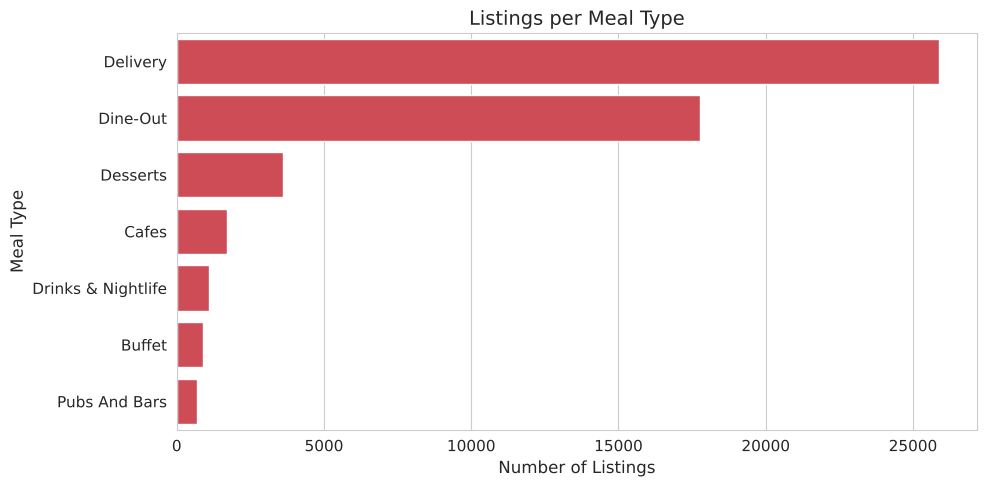

In [19]:
plt.figure(figsize=(10,5))

order = df["meal_type"].value_counts().index
sns.countplot(y="meal_type", data=df, order=order, color="#E23744")

plt.title("Listings per Meal Type")
plt.xlabel("Number of Listings")
plt.ylabel("Meal Type")

plt.tight_layout()
plt.show()

### Restaurant Type Distrb.

`rest_type` has ~90 unique vals , so will only plot the top 15.

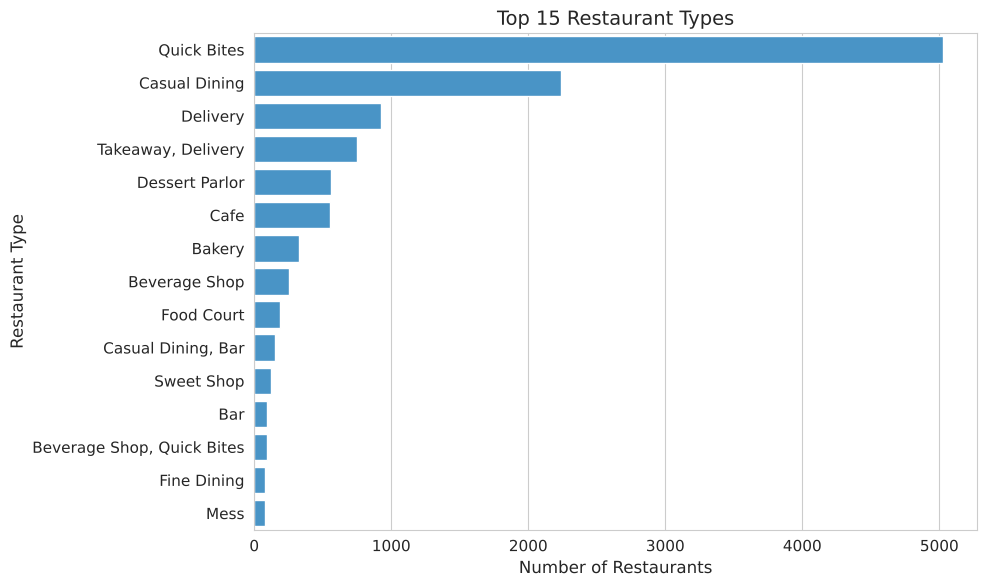

In [20]:
top_rest_types = df_unique["rest_type"].value_counts().head(15)

plt.figure(figsize=(10,6))
sns.barplot(x=top_rest_types.values, y=top_rest_types.index, color="#3498DB")

plt.title("Top 15 Restaurant Types")
plt.xlabel("Number of Restaurants")
plt.ylabel("Restaurant Type")

plt.tight_layout()
plt.savefig("plots/top_rest_types.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
# how much % do the top 5 types cover ?
share = df_unique["rest_type"].value_counts(normalize=True)
print("Top 5 rest types cover: ", f"{share.head(5).sum()*100:.1f}%", "of all restaurants")

Top 5 rest types cover:  76.0% of all restaurants


### Cuisines Distrb.

`cuisines` column is a **comma separated** list, eg : `"North Indian, Mughlai, Chinese"`.

So to count each cuisine we have to :
1. split by `","`
2. `explode()` -> one row per cuisine
3. strip the whitespaces

In [22]:
cuisine_series = (
    df_unique["cuisines"]
    .str.split(",")
    .explode()
    .str.strip()
)

print("Total unique cuisines: ", cuisine_series.nunique())

Total unique cuisines:  108


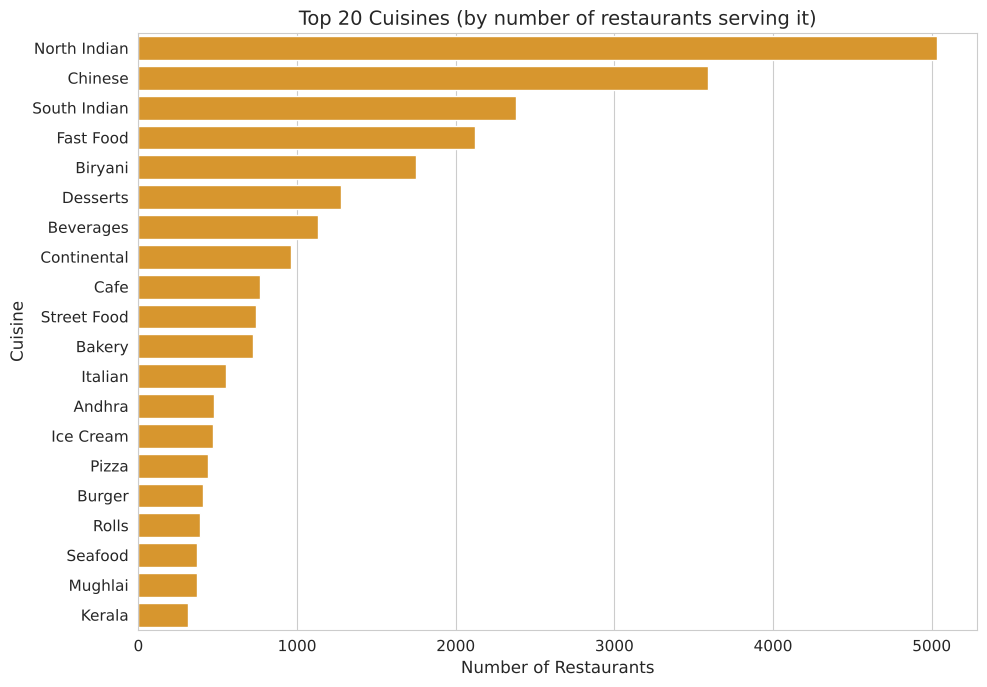

In [23]:
top_cuisines = cuisine_series.value_counts().head(20)

plt.figure(figsize=(10,7))
sns.barplot(x=top_cuisines.values, y=top_cuisines.index, color="#F39C12")

plt.title("Top 20 Cuisines (by number of restaurants serving it)")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine")

plt.tight_layout()
plt.savefig("plots/top_cuisines.png", dpi=150, bbox_inches="tight")
plt.show()

count    12498.000000
mean         2.307889
std          1.202716
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max          8.000000
Name: num_cuisines, dtype: float64


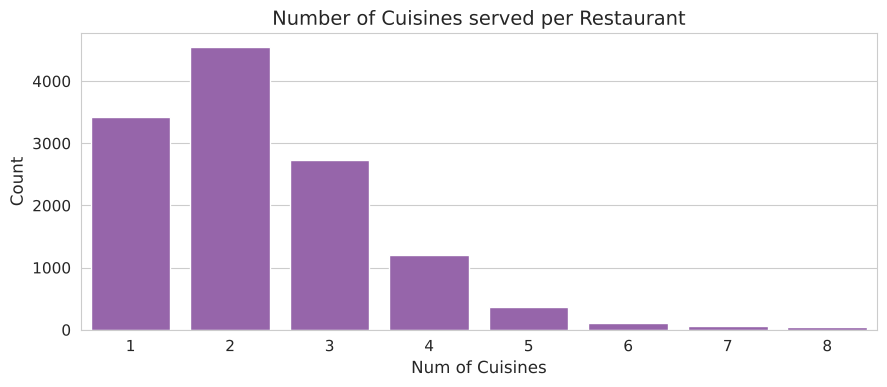

In [24]:
# how many cuisines does a restaurant serve ?
df_unique["num_cuisines"] = df_unique["cuisines"].str.split(",").apply(len)

print(df_unique["num_cuisines"].describe())

plt.figure(figsize=(9,4))
sns.countplot(x="num_cuisines", data=df_unique, color="#9B59B6")
plt.title("Number of Cuisines served per Restaurant")
plt.xlabel("Num of Cuisines")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

### Price Category Distrb.

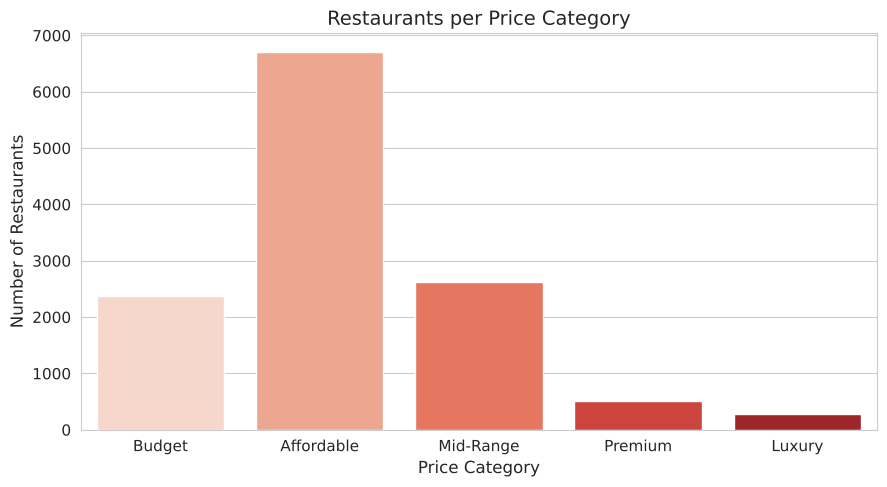

price_category
Budget        0.190
Affordable    0.537
Mid-Range     0.210
Premium       0.041
Luxury        0.023
Name: proportion, dtype: float64


In [25]:
plt.figure(figsize=(9,5))

sns.countplot(x="price_category", data=df_unique, order=price_order, palette="Reds")

plt.title("Restaurants per Price Category")
plt.xlabel("Price Category")
plt.ylabel("Number of Restaurants")

plt.tight_layout()
plt.show()

print(df_unique["price_category"].value_counts(normalize=True).reindex(price_order).round(3))

### Top Locations by Restaurant Count

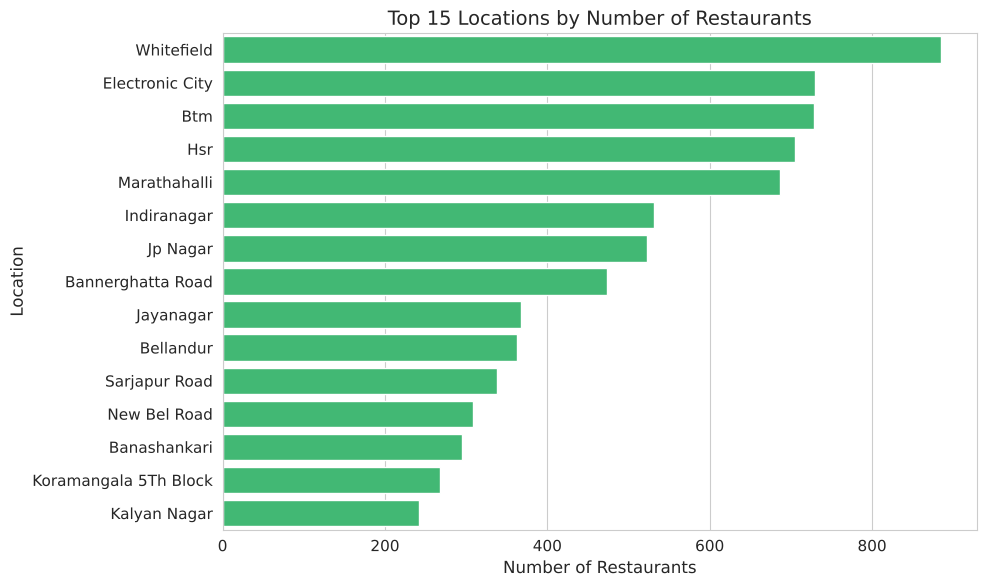

In [26]:
top_locations = df_unique["location"].value_counts().head(15)

plt.figure(figsize=(10,6))
sns.barplot(x=top_locations.values, y=top_locations.index, color="#2ECC71")

plt.title("Top 15 Locations by Number of Restaurants")
plt.xlabel("Number of Restaurants")
plt.ylabel("Location")

plt.tight_layout()
plt.savefig("plots/top_locations.png", dpi=150, bbox_inches="tight")
plt.show()

### Top Restaurant Chains

A "chain" = same `name` but different `address`.

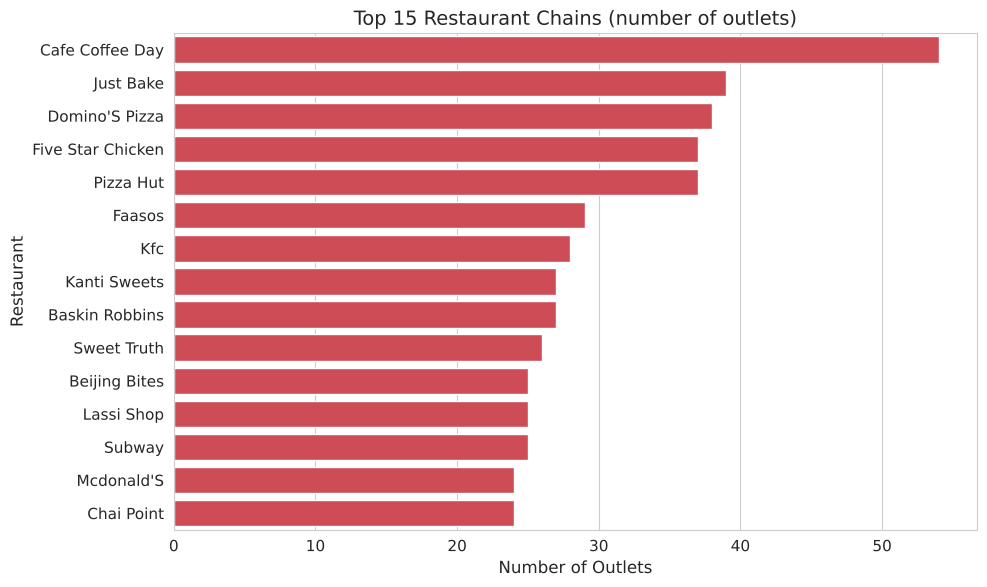

In [27]:
top_chains = df_unique["name"].value_counts().head(15)

plt.figure(figsize=(10,6))
sns.barplot(x=top_chains.values, y=top_chains.index, color="#E23744")

plt.title("Top 15 Restaurant Chains (number of outlets)")
plt.xlabel("Number of Outlets")
plt.ylabel("Restaurant")

plt.tight_layout()
plt.show()

-------------------------------------------------------
### Insights (Categorical Univariate) :

- **Online ordering** is common, ~53% of (unique) restaurants allow it.
- **Table booking** is rare, only ~7.6% restaurants offer it -> probably only the bigger / costly dine-in places.
- `Delivery` and `Dine-Out` dominate the `meal_type` listings.
- `Quick Bites` is by far the most common restaurant type, followed by `Casual Dining`. The top 5 types cover ~76% of the restaurants.
- `North Indian` and `Chinese` are the kings of Bangalore cuisines :) then South Indian, Fast Food, Biryani.
- Most restaurants serve **1-3 cuisines** (median = 2, max = 8).
- `Affordable` (Rs.201-500) is the biggest price segment (~54%), `Premium + Luxury` together are only ~6%.
- `Whitefield`, `Electronic City`, `BTM`, `HSR`, `Marathahalli` have the most restaurants (unique count).
- Chains like `Cafe Coffee Day` (54 outlets), `Just Bake`, `Domino's`, `Five Star Chicken`, `Pizza Hut` have lots of outlets.

-------------------------------------------------------

------------------------------------------------------------------------------

# Bivariate Analysis

Now we will check **relationship between 2 variables** at a time.

Main target variable for us is `rate`, because a recommender should recommend **good** restaurants.
So most of the questions are like "*does X affect rating ?*"

### Planned questions :
1. Does **online ordering** affect rating ?
2. Does **table booking** affect rating ?
3. Is there any relation between **cost** and **rating** ?
4. Is there any relation between **votes** and **rating** ?
5. Which **restaurant types** are rated highest ?
6. Which **locations** are rated highest ?
7. Which **cuisines** are rated highest ?
8. **Price category** vs Rating
9. **Meal type** vs Rating & Cost

> Reminder : for rating related plots we use `df_rated` (without fake median ratings).

### 1. Online Order vs Rating

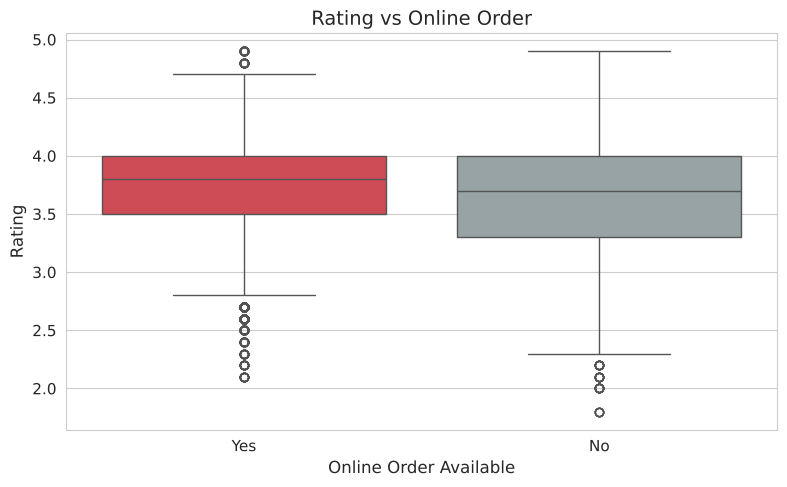

               mean  median  count
online_order                      
No            3.659     3.7  14462
Yes           3.722     3.8  27165


In [28]:
plt.figure(figsize=(8,5))

sns.boxplot(x="online_order", y="rate", data=df_rated, palette=["#E23744", "#95A5A6"])

plt.title("Rating vs Online Order")
plt.xlabel("Online Order Available")
plt.ylabel("Rating")

plt.tight_layout()
plt.show()

print(df_rated.groupby("online_order")["rate"].agg(["mean", "median", "count"]).round(3))

### 2. Table Booking vs Rating

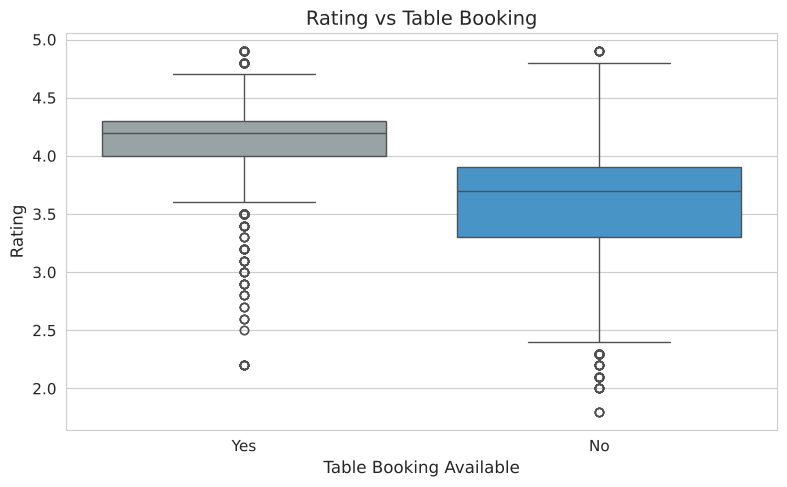

             mean  median  count
book_table                      
No          3.621     3.7  35337
Yes         4.142     4.2   6290


In [29]:
plt.figure(figsize=(8,5))

sns.boxplot(x="book_table", y="rate", data=df_rated, palette=["#95A5A6", "#3498DB"])

plt.title("Rating vs Table Booking")
plt.xlabel("Table Booking Available")
plt.ylabel("Rating")

plt.tight_layout()
plt.savefig("plots/rating_vs_book_table.png", dpi=150, bbox_inches="tight")
plt.show()

print(df_rated.groupby("book_table")["rate"].agg(["mean", "median", "count"]).round(3))

#### Is this difference statistically significant or just by chance ?

Will use **Mann-Whitney U test** (non-parametric, because ratings are not perfectly normal).

- `H0` : both groups have the same rating distribution
- `H1` : they are different

If `p-value < 0.05` -> reject H0.

In [30]:
from scipy.stats import mannwhitneyu

for col in ["online_order", "book_table"]:
    yes = df_rated[df_rated[col] == "Yes"]["rate"]
    no  = df_rated[df_rated[col] == "No"]["rate"]
    stat, p = mannwhitneyu(yes, no)
    print(f"{col:13s} -> p-value = {p:.2e}  | mean(Yes) = {yes.mean():.3f} , mean(No) = {no.mean():.3f}")

online_order  -> p-value = 2.03e-56  | mean(Yes) = 3.722 , mean(No) = 3.659
book_table    -> p-value = 0.00e+00  | mean(Yes) = 4.142 , mean(No) = 3.621


### 3. Cost vs Rating

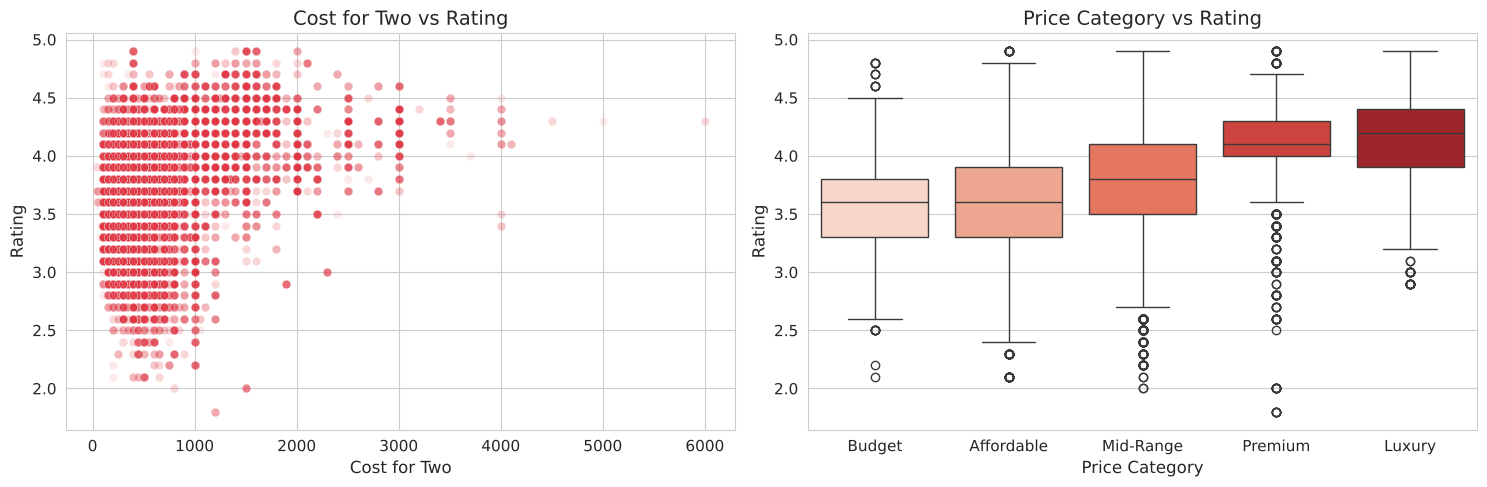

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# scatter with transparency because 40k points will overlap a lot
sns.scatterplot(x="cost_for_two", y="rate", data=df_rated, alpha=0.1, color="#E23744", ax=axes[0])
axes[0].set_title("Cost for Two vs Rating")
axes[0].set_xlabel("Cost for Two")
axes[0].set_ylabel("Rating")

sns.boxplot(x="price_category", y="rate", data=df_rated, order=price_order, palette="Reds", ax=axes[1])
axes[1].set_title("Price Category vs Rating")
axes[1].set_xlabel("Price Category")
axes[1].set_ylabel("Rating")

plt.tight_layout()
plt.savefig("plots/cost_vs_rating.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
print(df_rated.groupby("price_category")["rate"].agg(["mean", "median", "count"]).round(3))

                 mean  median  count
price_category                      
Budget          3.570     3.6   5170
Affordable      3.588     3.6  19636
Mid-Range       3.759     3.8  11707
Premium         4.114     4.1   3367
Luxury          4.156     4.2   1747


### 4. Votes vs Rating

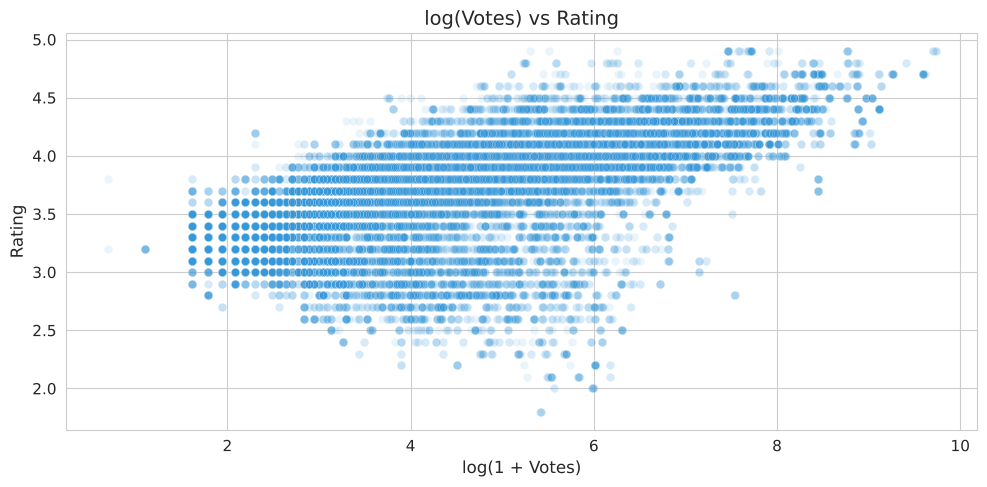

In [33]:
plt.figure(figsize=(10,5))

sns.scatterplot(x=np.log1p(df_rated["votes"]), y=df_rated["rate"], alpha=0.1, color="#3498DB")

plt.title("log(Votes) vs Rating")
plt.xlabel("log(1 + Votes)")
plt.ylabel("Rating")

plt.tight_layout()
plt.savefig("plots/votes_vs_rating.png", dpi=150, bbox_inches="tight")
plt.show()

In [34]:
# Pearson -> linear relation , Spearman -> monotonic relation (better for skewed data)

print("Pearson  (votes, rate): ", round(df_rated["votes"].corr(df_rated["rate"]), 3))
print("Spearman (votes, rate): ", round(df_rated["votes"].corr(df_rated["rate"], method="spearman"), 3))
print()
print("Pearson  (cost, rate) : ", round(df_rated["cost_for_two"].corr(df_rated["rate"]), 3))
print("Spearman (cost, rate) : ", round(df_rated["cost_for_two"].corr(df_rated["rate"], method="spearman"), 3))

Pearson  (votes, rate):  0.433
Spearman (votes, rate):  0.698

Pearson  (cost, rate) :  0.383
Spearman (cost, rate) :  0.393


### 5. Restaurant Type vs Rating

Only considering rest types with at least 200 rated listings (otherwise a type with 3 restaurants could top the chart just by luck).

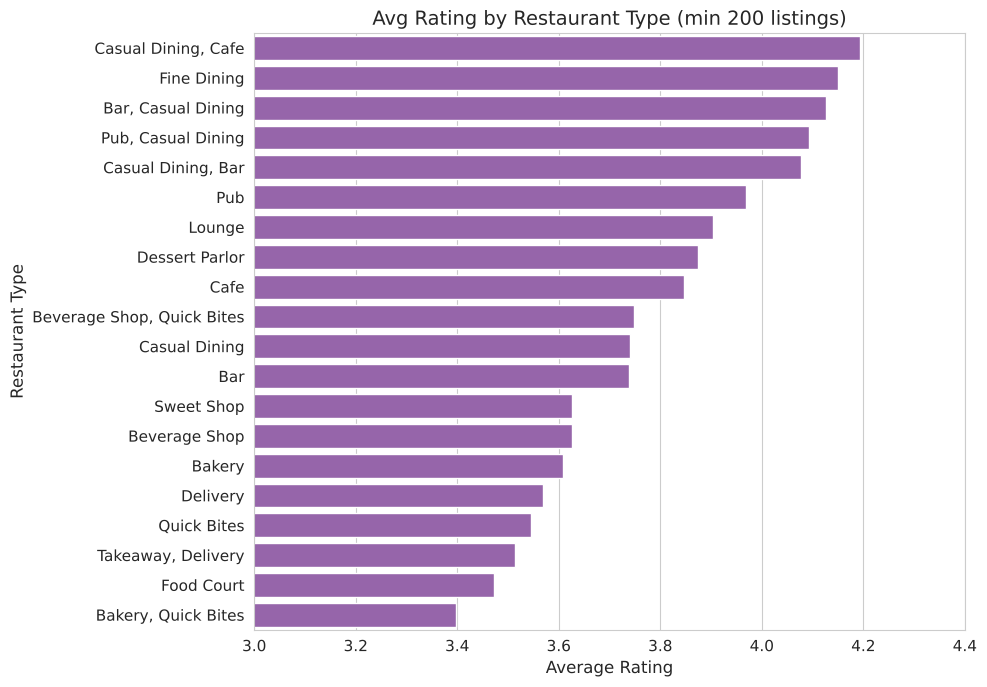

In [35]:
rest_stats = (
    df_rated.groupby("rest_type")["rate"]
    .agg(["mean", "count"])
    .query("count >= 200")
    .sort_values("mean", ascending=False)
)

plt.figure(figsize=(10,7))
sns.barplot(x=rest_stats["mean"], y=rest_stats.index, color="#9B59B6")

plt.title("Avg Rating by Restaurant Type (min 200 listings)")
plt.xlabel("Average Rating")
plt.ylabel("Restaurant Type")
plt.xlim(3, 4.4)

plt.tight_layout()
plt.savefig("plots/rating_by_rest_type.png", dpi=150, bbox_inches="tight")
plt.show()

### 6. Location vs Rating

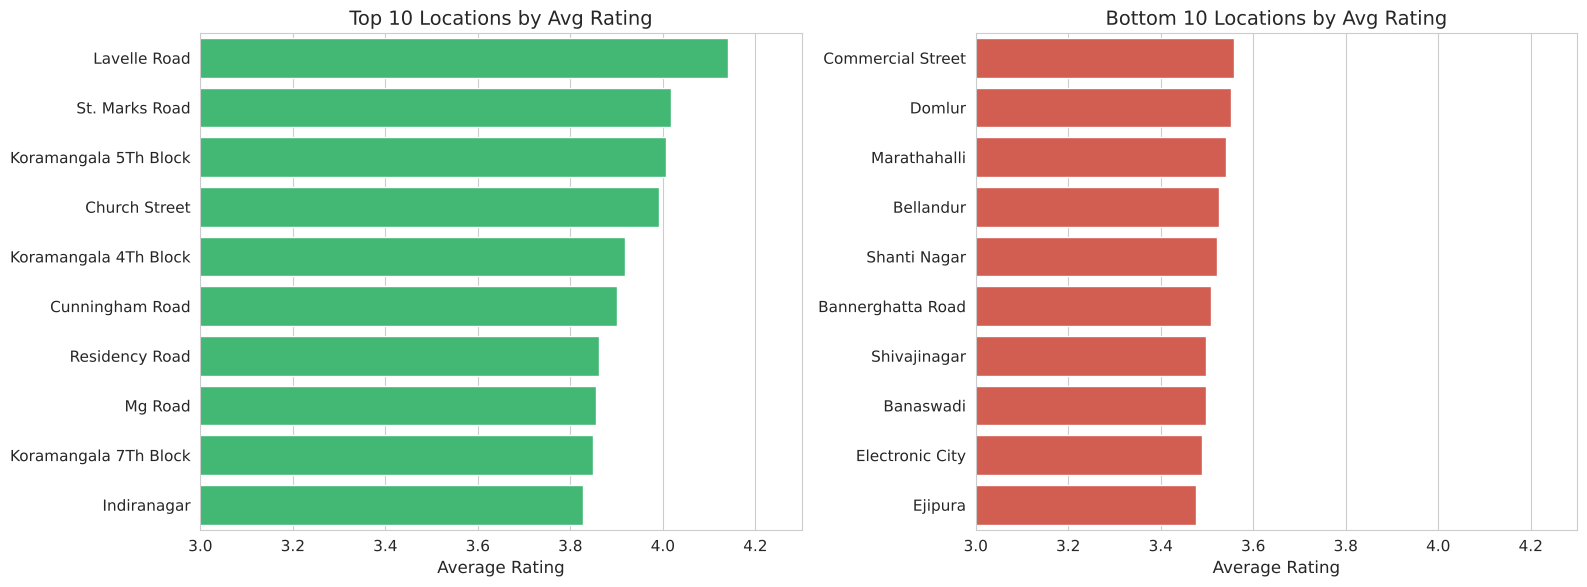

In [36]:
loc_stats = (
    df_rated.groupby("location")["rate"]
    .agg(["mean", "count"])
    .query("count >= 200")
    .sort_values("mean", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(x=loc_stats["mean"].head(10), y=loc_stats.index[:10], color="#2ECC71", ax=axes[0])
axes[0].set_title("Top 10 Locations by Avg Rating")
axes[0].set_xlabel("Average Rating")
axes[0].set_ylabel("")
axes[0].set_xlim(3, 4.3)

sns.barplot(x=loc_stats["mean"].tail(10), y=loc_stats.index[-10:], color="#E74C3C", ax=axes[1])
axes[1].set_title("Bottom 10 Locations by Avg Rating")
axes[1].set_xlabel("Average Rating")
axes[1].set_ylabel("")
axes[1].set_xlim(3, 4.3)

plt.tight_layout()
plt.savefig("plots/rating_by_location.png", dpi=150, bbox_inches="tight")
plt.show()

### 7. Cuisine vs Rating

Again `cuisines` is a list, so first explode it, then group by cuisine.

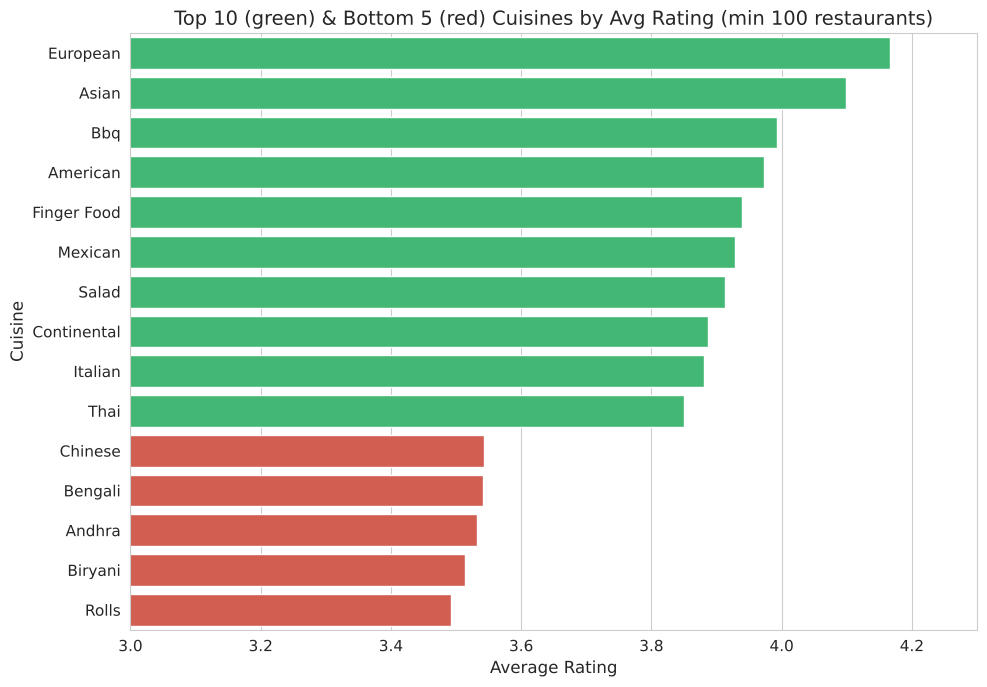

In [37]:
df_cuis = df_rated[["name", "address", "rate", "cuisines"]].drop_duplicates(subset=["name", "address"]).copy()
df_cuis["cuisine"] = df_cuis["cuisines"].str.split(",")
df_cuis = df_cuis.explode("cuisine")
df_cuis["cuisine"] = df_cuis["cuisine"].str.strip()

cuis_stats = (
    df_cuis.groupby("cuisine")["rate"]
    .agg(["mean", "count"])
    .query("count >= 100")
    .sort_values("mean", ascending=False)
)

plt.figure(figsize=(10,7))
top_bottom = pd.concat([cuis_stats.head(10), cuis_stats.tail(5)])
colors = ["#2ECC71"] * 10 + ["#E74C3C"] * 5
sns.barplot(x=top_bottom["mean"], y=top_bottom.index, palette=colors)

plt.title("Top 10 (green) & Bottom 5 (red) Cuisines by Avg Rating (min 100 restaurants)")
plt.xlabel("Average Rating")
plt.ylabel("Cuisine")
plt.xlim(3, 4.3)

plt.tight_layout()
plt.savefig("plots/rating_by_cuisine.png", dpi=150, bbox_inches="tight")
plt.show()

### 8. Meal Type vs Rating & Cost

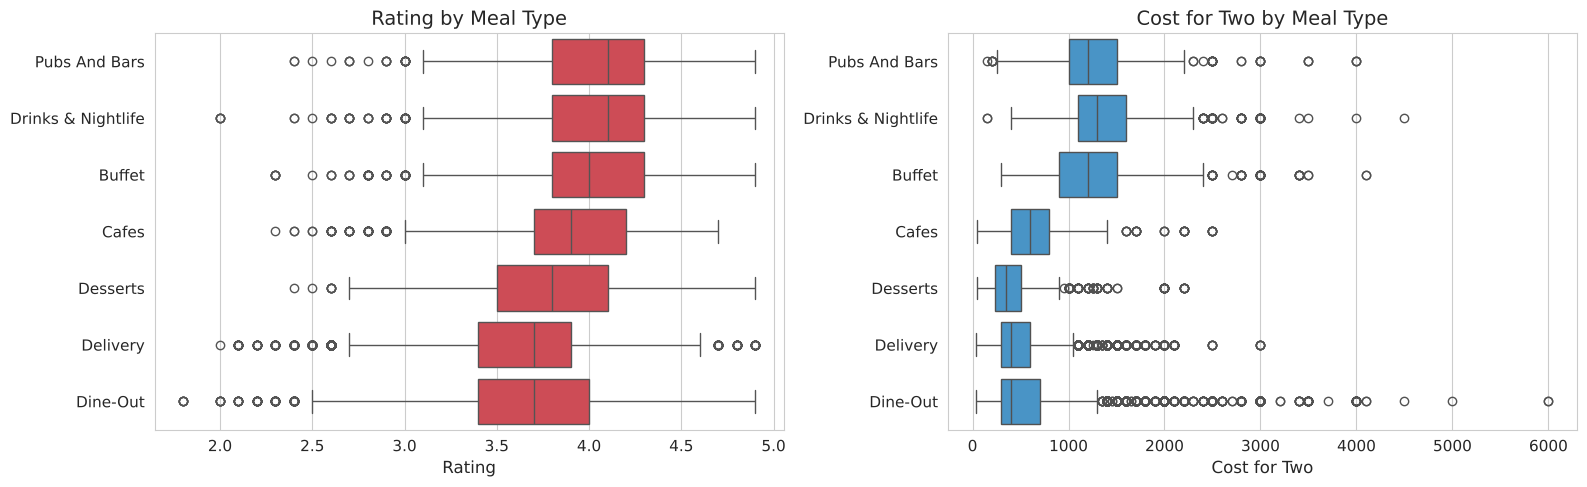

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

meal_order = df_rated.groupby("meal_type")["rate"].median().sort_values(ascending=False).index

sns.boxplot(x="rate", y="meal_type", data=df_rated, order=meal_order, color="#E23744", ax=axes[0])
axes[0].set_title("Rating by Meal Type")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("")

sns.boxplot(x="cost_for_two", y="meal_type", data=df, order=meal_order, color="#3498DB", ax=axes[1])
axes[1].set_title("Cost for Two by Meal Type")
axes[1].set_xlabel("Cost for Two")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

### 9. Online Order vs Table Booking (2 categoricals together)

In [39]:
ct = pd.crosstab(df_unique["online_order"], df_unique["book_table"], normalize="index").round(3)
print("Row-wise % : ")
ct

Row-wise % : 


book_table,No,Yes
online_order,,
No,0.923,0.077
Yes,0.925,0.075


-------------------------------------------------------
### Insights (Bivariate) :

- **Table booking** is the strongest single signal for higher rating. Restaurants with table booking are rated clearly higher (~4.1 vs ~3.6).
  These are mostly the bigger dine-in places, which are also more costly.
- **Online order** places have slightly higher rating (3.72 vs 3.66), the difference is small but statistically significant (huge sample size makes even small diffs significant, so dont over-read it).
- **Cost vs Rating** : positive but moderate relation. Costly places tend to be rated higher, but there are plenty of cheap places with great ratings also -> a recommender should NOT just push costly places.
  Avg rating jumps from ~3.57 (Budget) to ~4.16 (Luxury).
- **Votes vs Rating** : clear positive relation (Spearman = 0.70, much higher than Pearson 0.43 -> relation is monotonic but not linear). Highly voted restaurants are rarely badly rated. (popular places are popular for a reason ;) )
- **Restaurant type** : `Casual Dining, Cafe`, `Fine Dining`, `Bar, Casual Dining`, `Pub` type places top the ratings, while `Bakery, Quick Bites`, `Food Court`, `Takeaway, Delivery`, `Quick Bites` are at the bottom.
- **Location** : `Lavelle Road`, `St. Marks Road`, `Koramangala 5Th Block`, `Church Street` (central / premium areas) have the highest ratings, while `Ejipura`, `Electronic City`, `Banaswadi` are at the bottom.
- **Cuisine** : international cuisines (`European`, `Asian`, `Bbq`, `American` ...) are rated higher, while `Rolls`, `Biryani`, `Andhra`, `Chinese`, `Fast Food` sit lower on average - mostly because they are served by lots of cheap quick-bite places.
- `Drinks & Nightlife` and `Pubs And Bars` have both the highest ratings (median 4.1) and highest cost (median Rs.1200-1300).
- `online_order` and `book_table` are almost **independent** of each other (~7.5% table booking in both groups).

-------------------------------------------------------

------------------------------------------------------------------------------

# Multivariate Analysis

Now looking at **more than 2 variables** together.

1. Correlation heatmap of numerical columns
2. Rating by Price Category **and** Table Booking
3. Location x Price Category pivot
4. Pairplot (on a sample)

### 1. Correlation Heatmap

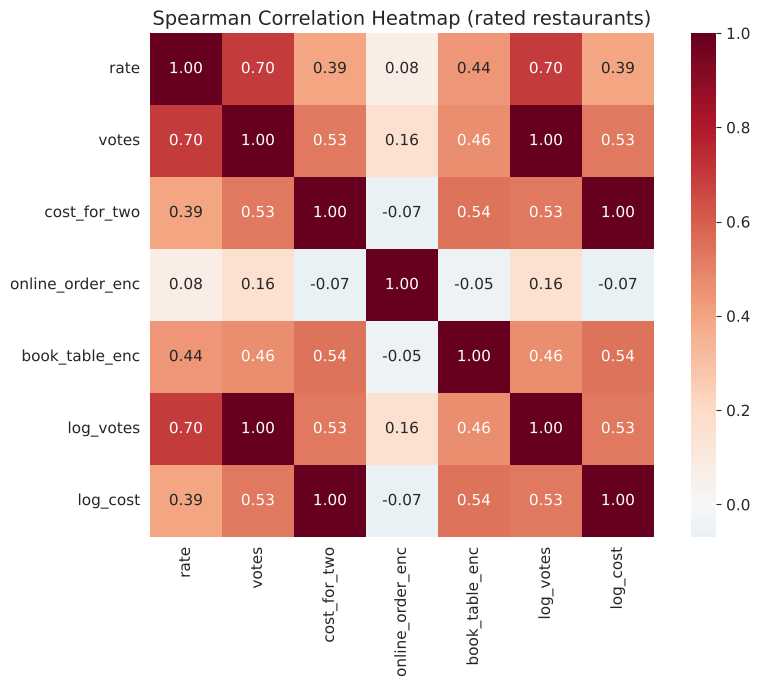

In [40]:
num_cols = ["rate", "votes", "cost_for_two", "online_order_enc", "book_table_enc"]

corr_df = df_rated[num_cols].copy()
corr_df["log_votes"] = np.log1p(corr_df["votes"])
corr_df["log_cost"] = np.log1p(corr_df["cost_for_two"])

plt.figure(figsize=(9,7))
sns.heatmap(
    corr_df.corr(method="spearman"),
    annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True
)
plt.title("Spearman Correlation Heatmap (rated restaurants)")
plt.tight_layout()
plt.savefig("plots/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

> Note : log transform doesn't change Spearman correlation (it only depends on the order / rank),
that's why `votes` & `log_votes` give the same numbers. Just added them to show this ;)

### 2. Rating by Price Category & Table Booking

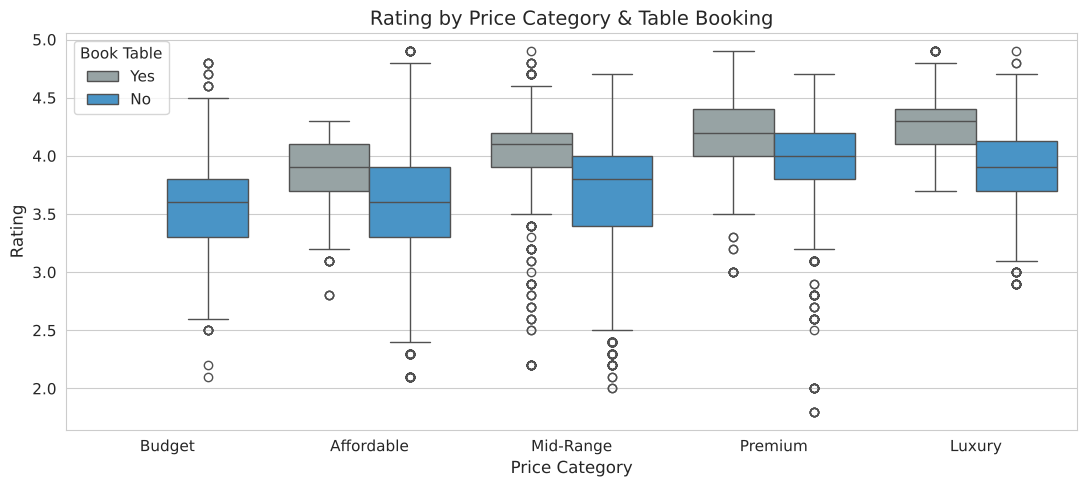

In [41]:
plt.figure(figsize=(11,5))

sns.boxplot(
    x="price_category", y="rate", hue="book_table",
    data=df_rated, order=price_order, palette=["#95A5A6", "#3498DB"]
)

plt.title("Rating by Price Category & Table Booking")
plt.xlabel("Price Category")
plt.ylabel("Rating")
plt.legend(title="Book Table")

plt.tight_layout()
plt.show()

In [42]:
pd.pivot_table(
    df_rated, values="rate", index="price_category",
    columns="book_table", aggfunc="mean", observed=False
).round(3)

book_table,No,Yes
price_category,,
Budget,3.570,NaN
Affordable,3.586,3.821
Mid-Range,3.679,4.063
Premium,3.935,4.186
Luxury,3.895,4.248


### 3. Location x Price Category

What is the price mix of the top 10 locations ?

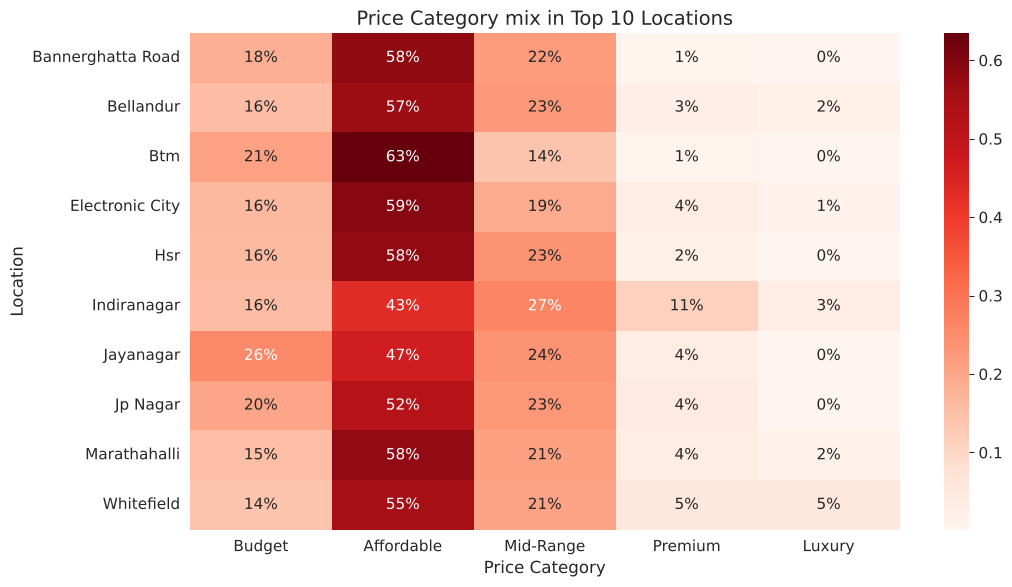

In [43]:
top10_loc = df_unique["location"].value_counts().head(10).index

loc_price = pd.crosstab(
    df_unique[df_unique["location"].isin(top10_loc)]["location"],
    df_unique[df_unique["location"].isin(top10_loc)]["price_category"],
    normalize="index"
)

plt.figure(figsize=(11,6))
sns.heatmap(loc_price, annot=True, fmt=".0%", cmap="Reds")
plt.title("Price Category mix in Top 10 Locations")
plt.xlabel("Price Category")
plt.ylabel("Location")
plt.tight_layout()
plt.savefig("plots/location_price_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### 4. Pairplot

Pairplot on 40k rows would be very slow, so taking a random sample of 3000 rows.

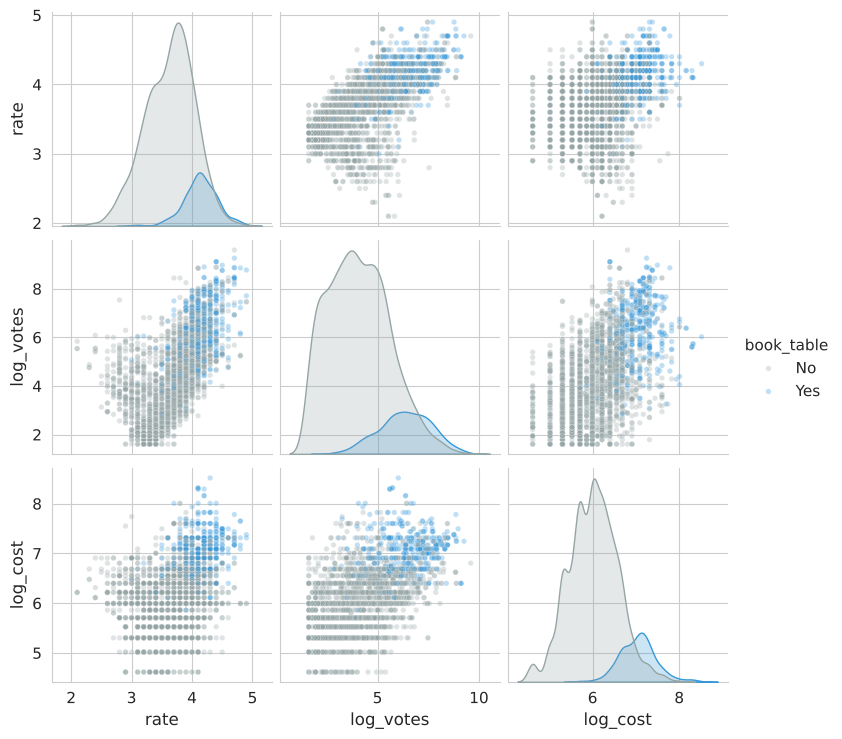

In [44]:
sample = df_rated.sample(3000, random_state=42).copy()
sample["log_votes"] = np.log1p(sample["votes"])
sample["log_cost"] = np.log1p(sample["cost_for_two"])

sns.pairplot(
    sample[["rate", "log_votes", "log_cost", "book_table"]],
    hue="book_table", palette=["#95A5A6", "#3498DB"],
    plot_kws={"alpha": 0.3, "s": 15}, diag_kind="kde"
)
plt.show()

-------------------------------------------------------
### Insights (Multivariate) :

- From the heatmap : `rate` is most correlated with `votes` (0.70), then `book_table` (0.44) and `cost` (0.39). `online_order` barely matters (0.08).
- `cost_for_two` and `book_table` are also correlated with each other (0.54) -> costly places offer table booking.
  So part of the "cost effect" on rating is actually the "dine-in / table booking" effect.
- Within the **same price category**, restaurants with table booking still have higher ratings (eg : Premium -> 4.19 vs 3.94) -> book_table carries its own info.
- Budget share is highest in `Jayanagar` & `Btm`, while `Whitefield` & `Indiranagar` have relatively more Premium / Luxury places.

-------------------------------------------------------

------------------------------------------------------------------------------

# Final Summary of EDA (Part 1 + Part 2)

### What we learned about the data :
1. Same restaurant is repeated ~4 times (different `meal_type` / `city` listings) -> for the recommender we must work at **restaurant level** (one row per restaurant).
2. ~20% restaurants are **unrated** (`votes == 0`), their `3.7` rating is fake (median filled). We should treat them separately.
3. `cost_for_two` and `votes` are heavily **right skewed** -> use log transforms.
4. Rating is mostly affected by : **popularity (votes)**, **table booking**, **cost**, **restaurant type** & **location**.
5. `cuisines` is a multi-valued text column -> needs special encoding (multi-hot / TF-IDF), not simple label encoding.

### How this helps the Recommendation System :
- Raw rating alone is not enough. A restaurant with `4.9` from 5 votes is less trustworthy than `4.5` from 5000 votes
  => we will build a **weighted rating** (like IMDB top 250 formula) in the next notebook.
- Users usually search by **location + cuisine + budget**, so these 3 will be the main filters / features.
- Restaurant **similarity** can be built from cuisines + rest_type + price + location.

-------------------------------------------------------------
### Next notebook -> `03_Feature_Engineering.ipynb`